### It implements a full cycle from defining the geometry of the catenary curve analytically to constructing a PSF image.

*Note*

1. Using the N parameter, we determine the number of cell layers, the more of them, the better the light collection.
2. The parameter N must be even., 0 - 2 - 4 - 6 - 8 - 10
3. The coordinate without a pair is the middle of the symmetry of each order.
4. M - defines the number of orders. The more of them there are, the more light is collected. The long-range orders become very small.
5. big-center - Determines the number of curves for the first order (most intensive)

In [1]:
import meep as mp
import numpy as np
import conf
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.interpolate import interp1d
from matplotlib.colors import Normalize

# Simulation parameters for MEEP
X_cell_size = conf.cell_X # Width of simulation doesn't effect on lense.
Y_cell_size = 2.5*1e3 # Aperture is 1 mm
cell = mp.Vector3(X_cell_size, Y_cell_size, 0)  # размер области симуляции
pml_layers = [mp.PML(thickness=conf.pml, direction=mp.X, side=mp.ALL)]
sources = [mp.Source(
    mp.ContinuousSource(frequency=conf.inc_fcen, fwidth=conf.inc_df, end_time = conf.end_time/4),
    component=mp.Ez,
    center=conf.source_center,
    size=mp.Vector3(x=0, y=Y_cell_size, z=0),
)]

# All parameters related to the definition of geometry
M = 41 # the number of radial layers.
big_center = True
N_for_big_center = 40
N = 20 # N must be even., 0 - 2 - 4 - 6 - 8 - 10
LIMIT_PRODUCT = 0.1 # Limitation 200 nm. Geometry can't be larger this size.

k = 2 * np.pi / conf.inc_wavelength # wave number
f = 5*1e3 # focal length 20 mm
Q = 300 # curve detailing. It has almost no effect on the result
w = 0.1 # 100 nm. The width of the gap between the curves

if big_center:
    x_sections_coordinates = np.zeros((M,N_for_big_center,4))
else: x_sections_coordinates = np.zeros((M,N+1,4))

geometry = []

# sub
geometry.append(mp.Block(
    material=conf.in_material,
    size=mp.Vector3(conf.in_sub, mp.inf, 0),
    center=mp.Vector3(conf.sub_center.x),
))

# Precompute radii
rt = np.sqrt(4 * f * (-np.pi / 2 + np.arange(1, M+1) * np.pi) / k)


# Define the function to integrate
def fun(x):
    return np.tan((k * x ** 2) / (4 * f))
def zero_derivative (m):
    calculation = np.sqrt((4 * f * m * np.pi)/k)
    return calculation
def get_y_section(y0, curves):
    """
    Получить срез кривых плоскостью Y = y0.

    :param y0: Значение Y для среза.
    :param curves: Список массивов с координатами кривых [(x1, y1), (x2, y2), ...].
    :return: Координата (x) для пересечения.
    """
    sections = np.zeros(shape=4)
    n=0
    for curve in curves:
        x_vals, y_vals = curve
        x_first_center = 0
        for i in range(len(y_vals) - 1):           
            y1, y2 = y_vals[i], y_vals[i + 1]
            x1, x2 = x_vals[i], x_vals[i + 1]         
            if y1 <= y0 <= y2 or y2 <= y0 <= y1:
                # Линейная интерполяция для x
                x_interp = x1 + (y0 - y1) * (x2 - x1) / (y2 - y1)
                if x_first_center != x_interp: sections[n] = x_interp
                x_first_center = x_interp
                n = n + 1
                
    return sections

# Main loop for layers
for m in range(M):
    rt0 = 0 if m == 0 else rt[m - 1] + 0.1
    x = np.linspace(rt0, rt[m] - 0.01, Q)
    # Compute y values by integration
    y = np.array([quad(fun, rt0, xi)[0] for xi in x])
    yy = np.empty((N_for_big_center, 2), dtype=object)
    
    xt = x.copy()
    ip = np.argmin(y)
    y1 = y - y[ip]
    y11 = y1.copy()
    y2 = y11 - w
    
    print(f"Circle {m}")
    
    if big_center:
        SECTION = w*N_for_big_center
        #Здесь мы собираем все кривые принадлежащие данному порядку
        for n in range(N_for_big_center):
            curves = []
            yy[n, 0] = y1 + 2 * n * w # Верхняя кривая 
            yy[n, 1] = y2 + 2 * n * w # Нижняя кривая
                 
            # Формируем кривые
            curves.append((xt, yy[n,0]))
            curves.append((xt, yy[n,1]))
            
            # Получаем срез при Y = SECTION
            x_sections_coordinates[m, n] = get_y_section(SECTION, curves)
            print(f"Section: {n} :", x_sections_coordinates[m,n])
            
        big_center = False
    
    else:
        SECTION = w*N
        for n in range(N):
            curves = []
            yy[n, 0] = y1 + 2 * n * w # Верхняя кривая 
            yy[n, 1] = y2 + 2 * n * w # Нижняя кривая
                 
            # Формируем кривые
            curves.append((xt, yy[n,0]))
            curves.append((xt, yy[n,1]))
            
            # Получаем срез при Y = SECTION
            x_sections_coordinates[m, n] = get_y_section(SECTION, curves)
            print(f"Section: {n} :", x_sections_coordinates[m,n])
   

substrait begin in -2.25 and end -1.25
atom begin in -1.25 and end 0.75
flux_center begin in 1.75
at_center is -0.25
sub_center is -1.75
resolution is 1
end_time is 11
Circle 0
Section: 0 : [51.95665823 52.38181993  0.          0.        ]
Section: 1 : [51.08421024 51.52423174  0.          0.        ]
Section: 2 : [50.17997826 50.63624709  0.          0.        ]
Section: 3 : [49.24097417 49.71502129  0.          0.        ]
Section: 4 : [48.26389657 48.75741417  0.          0.        ]
Section: 5 : [47.24387993 47.75993563  0.          0.        ]
Section: 6 : [46.17613779 46.71613573  0.          0.        ]
Section: 7 : [45.05696219 45.62328978  0.          0.        ]
Section: 8 : [43.87606238 44.47438202  0.          0.        ]
Section: 9 : [42.62789337 43.26176055  0.          0.        ]
Section: 10 : [41.30065315 41.9748264   0.          0.        ]
Section: 11 : [39.88022189 40.60299784  0.          0.        ]
Section: 12 : [38.34961672 39.13107004  0.          0.        ]
S

All necessary geometry data obtained from the section is accumulated in x_sections_coordinates. Now it is only necessary to process them correctly.

In [2]:
list_of_centers = []
list_of_widths = []

def get_width_first_order(x_sections_coordinates):
    result = []
    for n in range(N_for_big_center): 
        if x_sections_coordinates[0, n, 0] == 0:
            # Добавляем width_first_order
            width_first_order = x_sections_coordinates[0, n, 1] * 2
            result.append(width_first_order)
            return result  # Завершаем функцию сразу после нахождения значения
        else:
            # Вычисляем ширину и добавляем её в список
            width = abs(x_sections_coordinates[0, n, 0] - x_sections_coordinates[0, n, 1])
            result.append(width)

def get_centers_first_order(x_sections_coordinates):
    result = []
    for n in range(N_for_big_center):
        if x_sections_coordinates[0, n, 0] == 0:
            first_center = 0
            result.append(first_center)
            return result
        else:
            another_center = abs(x_sections_coordinates[0, n, 0] + x_sections_coordinates[0, n, 1]) /2
            result.append(another_center)
            
def get_width_other_order(x_sections_coordinates,m):
    result = []
    for n in range(N):
        if (x_sections_coordinates[m,n,0] != 0) and (x_sections_coordinates[m,n,1] == 0) and (x_sections_coordinates[m,n+1,0] == 0):
            third = abs(x_sections_coordinates[m,n,2] - x_sections_coordinates[m,n,3])
            result.append(third)
            return result  
        if x_sections_coordinates[m,n,0] == 0 or x_sections_coordinates[m,n,0] == 0:
            continue
        if x_sections_coordinates[m,n,2] != 0:
            first = abs(x_sections_coordinates[m,n,0] - x_sections_coordinates[m,n,2])
            result.append(first)       
        if x_sections_coordinates[m,n,3] != 0:
            second = abs(x_sections_coordinates[m,n,1] - x_sections_coordinates[m,n,3])
            result.append(second)
          
def get_center_of_other_order(x_sections_coordinates, m):
    result = []
    for n in range(N):
        if (x_sections_coordinates[m,n,0] != 0) and (x_sections_coordinates[m,n,1] == 0) and (x_sections_coordinates[m,n+1,0] == 0):
            center = zero_derivative(m)
            result.append(center)
            return result         
        
        if x_sections_coordinates[m,n,0] == 0 or x_sections_coordinates[m,n,0] == 0:
            continue        
        if x_sections_coordinates[m,n,2] != 0:
            first = (x_sections_coordinates[m,n,0] + x_sections_coordinates[m,n,2])/2
            result.append(first)
        if x_sections_coordinates[m,n,3] != 0:
            second = (x_sections_coordinates[m,n,1] + x_sections_coordinates[m,n,3])/2
            result.append(second) 

for m in range(1,M):
    other_center = get_center_of_other_order(x_sections_coordinates, m)
    other_width = get_width_other_order(x_sections_coordinates, m)
    list_of_centers.append(other_center)
    list_of_widths.append(other_width)

In [3]:
list_of_centers.insert(0,get_centers_first_order(x_sections_coordinates))
list_of_widths.insert(0,get_width_first_order(x_sections_coordinates))

Getters for widths and centers are ready, now you can assemble the geometry.
The main centers are calculated as accurately as possible through derivatives. But the widths and centers of the additional sections are based on interpolation, which can introduce distortions and which can be improved in the future.

In [4]:
# A test to check the basic parameters. The length of the widths at each radius (in each order should be equal to the length of the centers)
for i in range (len(list_of_centers)):
    for j in range(len(list_of_centers[i])):
        if list_of_centers[i][j] != list_of_centers[i][j]:
            ValueError("List elements do not match")
print("Checked")

Checked


In [5]:
# Function for recursive traversal of all nested lists
def flatten(lst):
    for item in lst:
        if isinstance(item, list):
            # Если элемент - это список, рекурсивно обрабатываем его
            yield from flatten(item)
        else:
            # Если элемент не список, возвращаем его
            yield item

# Getting all the items from the nested lists
flat_centers = list(flatten(list_of_centers))
flat_widths = list(flatten(list_of_widths))

# # Let's put it all into geometry now
for i in range(len(flat_centers)):
    if flat_widths[i] < LIMIT_PRODUCT:
        continue
    else:
        geometry.append(mp.Block(
            material=conf.at_material,
            size=mp.Vector3(x=conf.at_hei, y=flat_widths[i], z=0), 
            center=mp.Vector3(x=conf.at_center.x, y=flat_centers[i], z=0)
        ))
        
    # We use symmetry, hence dont need negative side
    
    # #Another side
    # if flat_widths[i] < LIMIT_PRODUCT:
    #     continue
    # else:
    #     geometry.append(mp.Block(
    #         material=conf.at_material,
    #         size=mp.Vector3(x=conf.at_hei, y=flat_widths[i], z=0), 
    #         center=mp.Vector3(x=conf.at_center, y=-flat_centers[i], z=0)
    #     ))   

     block, center = (-1.75,0,0)
          size (1,1e+20,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (6.5,6.5,6.5)
     block, center = (-0.25,52.1692,0)
          size (2,0.425162,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (6.5,6.5,6.5)
     block, center = (-0.25,51.3042,0)
          size (2,0.440022,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (6.5,6.5,6.5)
     block, center = (-0.25,50.4081,0)
          size (2,0.456269,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (6.5,6.5,6.5)
     block, center = (-0.25,49.478,0)
          size (2,0.474047,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (6.5,6.5,6.5)
     block, center = (-0.25,48.5107,0)
          size (2,0.493518,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsil



In [6]:
sim = mp.Simulation(
    cell_size=cell,
    boundary_layers=pml_layers,
    geometry=geometry,
    sources=sources,
    k_point=conf.k_point,
    resolution=conf.min_resolution * 5,
    split_chunks_evenly=False,
    symmetries = [mp.Mirror(mp.Y)]
    
)

# Adding a near2far area
near2far_region = sim.add_near2far(
    conf.inc_fcen,  # центральная частота
    0,      # ширина спектра
    1,
    mp.Near2FarRegion(center=conf.flux_center, size=mp.Vector3(y=Y_cell_size)),
)

plt.figure(figsize=(1, 150))
sim.plot2D(
    output_plane = mp.Volume(center=mp.Vector3(0,0,0), size=mp.Vector3(cell[0], cell[1],0))
)
plt.savefig("precomp_near_plot.png", dpi = 150)  # Сохранение изображения в файл
plt.show()  # Отображение изображения

In [7]:
# Running the simulation
sim.run(until = conf.end_time)

-----------
Initializing structure...
Halving computational cell along direction y
time for choose_chunkdivision = 0.00328183 s
Working in 2D dimensions.
Computational cell is 11.6 x 2500 x 0 with resolution 5
     block, center = (-1.75,0,0)
          size (1,1e+20,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (6.5,6.5,6.5)
     block, center = (-0.25,52.1692,0)
          size (2,0.425162,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (6.5,6.5,6.5)
     block, center = (-0.25,51.3042,0)
          size (2,0.440022,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (6.5,6.5,6.5)
     block, center = (-0.25,50.4081,0)
          size (2,0.456269,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (6.5,6.5,6.5)
     block, center = (-0.25,49.478,0)
          size (2,0.474047,0)
          axes (1,0,0), (0,1,0), (0,0,1

FloatProgress(value=0.0, description='0% done ', max=11.0)

run 0 finished at t = 11.0 (110 timesteps)


In [8]:
spot_size = Y_cell_size # actual size in micrometers
ff_res = conf.resolution_img/spot_size # resolution of the calculated field

# Calculating fields in the far zone
far_field = sim.get_farfields(
    near2far_region,
    ff_res,
    center=mp.Vector3(x=conf.flux_center[0] + f),
    size = mp.Vector3(y=spot_size)
)
Ez_far_field = abs(far_field["Ez"])**2

get_farfields_array working on point 315 of 800 (39% done), 0.0127009 s/point
get_farfields_array working on point 642 of 800 (80% done), 0.0122477 s/point


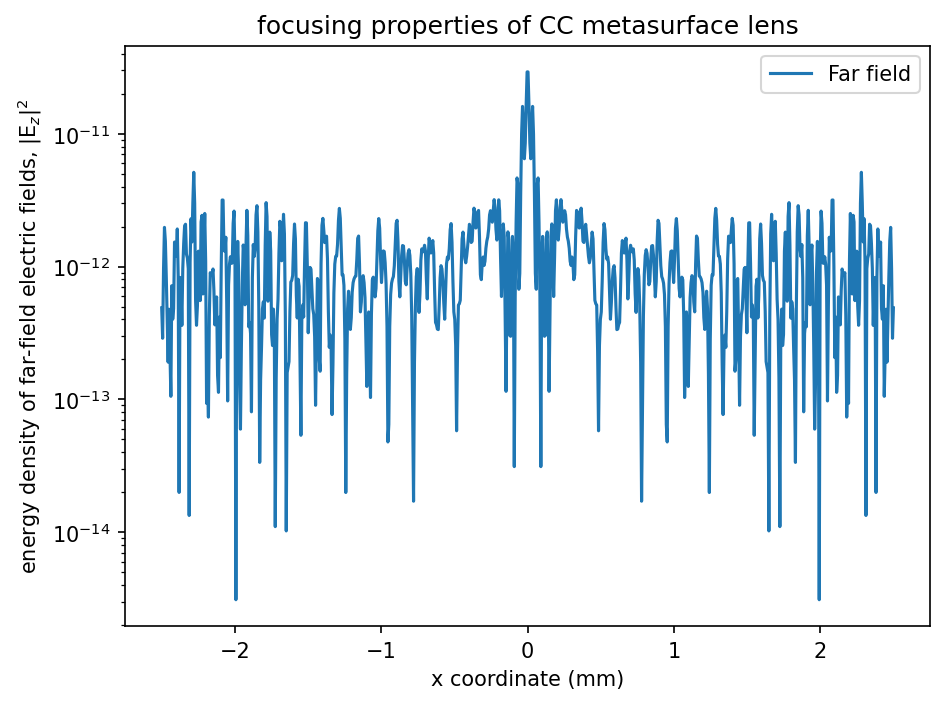

In [9]:
x = np.linspace(
    -spot_size,
    +spot_size,
    conf.resolution_img,
)

plt.figure(dpi=150)
plt.semilogy(
    x*1e-3, Ez_far_field, label="Far field"
)
plt.xlabel("x coordinate (mm)")
plt.ylabel(r"energy density of far-field electric fields, |E$_z$|$^2$")
plt.title("focusing properties of CC metasurface lens")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

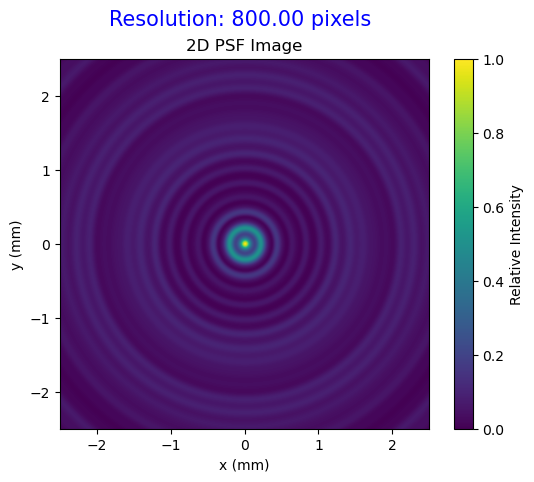

In [15]:
# Интерполяция данных интенсивности для получения значений на любых радиусах
interp_func = interp1d(x, Ez_far_field, kind='cubic', fill_value="extrapolate")

# The dimension of the image should be correlated with the dimension of x, so as not to lose touch with the actual dimensions
image_size = len(x)
center = image_size // 2

# Empty matrix
image = np.zeros((image_size, image_size))

# Заполнение изображения на основе радиусов
for i in range(image_size):
    for j in range(image_size):
        r = np.sqrt((i - center)**2 + (j - center)**2)  # Вычисление радиуса
        image[i, j] = interp_func(r)  # Применение интерполированной интенсивности

# Normalization of intensity in the range from 0 to 1
norm = Normalize(vmin=np.min(image), vmax=np.max(image))
normalized_image = norm(image)

# Visualization of the result
plt.imshow(normalized_image, cmap='viridis', origin='lower', extent=[x[0]*1e-3, x[-1]*1e-3, x[0]*1e-3, x[-1]*1e-3])
plt.colorbar(label='Relative Intensity')
plt.title("2D PSF Image")
plt.xlabel("x (mm)")
plt.ylabel("y (mm)")
plt.figtext(0.5, 0.95, "Resolution: {:.2f} pixels".format(conf.resolution_img), 
            ha="center", fontsize=12, color="blue")
plt.show()